# Notebook 03 — Image Augmentation (تحسين البيانات بالصور)

## Purpose

Data augmentation generates transformed copies of training images (and their
bounding boxes) to make a model more robust. In object detection, every geometric
transform must be applied to the image **and** the boxes together, or the labels stop
matching the pixels. This notebook focuses on the under-represented
`life_saving_appliances` class (class 3, ~923 training instances).

### Key concepts

- **Image-level augmentation** transforms whole images (flip, rotate, brightness).
- **Instance counts** count individual bounding boxes, which is different from image
  counts (one image can hold many objects).
- **Class-aware sampling / augmentation** targets a specific class (here class 3).
- **Augmentation cannot create real diversity** — it only reuses existing pixels, so
  it cannot invent new object appearances, lighting, or backgrounds.

### الشرح بالعربية

تحسين البيانات (Data Augmentation) يولّد نسخًا معدّلة من صور التدريب وصناديقها لزيادة
متانة النموذج. في كشف الأجسام، يجب تطبيق أي تحويل هندسي على الصورة **والصناديق معًا**




## Section 2 — Environment and Dataset Verification

### Purpose

Confirm the environment, dataset paths, class mapping, counts, and label integrity
before any augmentation.

### Expected output

Versions, path checks, per-class object/image counts, box-size statistics, and any
validation issues (missing/malformed/duplicate rows).

### Failure conditions

A missing YAML, wrong class mapping, or missing image/label directory prints an
actionable error and stops.

### بالعربية

التحقق من البيئة والمسارات وتعيين الفئات وعدد العيّنات وسلامة التسميات قبل البدء.

In [5]:
from pathlib import Path
import cv2
import numpy as np
import PIL
import matplotlib
import yaml
import sys

print("Python:", sys.version.split()[0])
print("OpenCV (cv2):", cv2.__version__)
print("NumPy:", np.__version__)
print("Pillow:", PIL.__version__)
print("Matplotlib:", matplotlib.__version__)
print("PyYAML:", yaml.__version__)

PROJECT = Path("E:/lifeguardDron")
DATASET_YAML = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2" / "dataset.yaml"
TRAIN_IMAGES = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2" / "images" / "train"
TRAIN_LABELS = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2" / "labels" / "train"
VAL_IMAGES = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2" / "images" / "val"
VAL_LABELS = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2" / "labels" / "val"
NAMES = {0: "swimmer", 1: "boat", 2: "jetski", 3: "life_saving_appliances", 4: "buoy"}

def require(cond, msg):
    if not cond:
        raise SystemExit("PRECHECK FAILED: " + msg)
    print("  OK  " + msg)

require(DATASET_YAML.exists(), "dataset.yaml exists")
cfg = yaml.safe_load(DATASET_YAML.read_text(encoding="utf-8"))
print("  nc:", cfg["nc"], "| names:", cfg["names"])
require(cfg["names"] == NAMES, "class mapping matches the expected 5-class order")

for name, p in [("train images", TRAIN_IMAGES), ("train labels", TRAIN_LABELS),
                ("val images", VAL_IMAGES), ("val labels", VAL_LABELS)]:
    require(p.exists() and p.is_dir(), name + " exists: " + str(p))

Python: 3.11.4
OpenCV (cv2): 5.0.0
NumPy: 2.4.4
Pillow: 12.2.0
Matplotlib: 3.10.9
PyYAML: 6.0.3
  OK  dataset.yaml exists
  nc: 5 | names: {0: 'swimmer', 1: 'boat', 2: 'jetski', 3: 'life_saving_appliances', 4: 'buoy'}
  OK  class mapping matches the expected 5-class order
  OK  train images exists: E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\images\train
  OK  train labels exists: E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\labels\train
  OK  val images exists: E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\images\val
  OK  val labels exists: E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\labels\val


In [6]:
from collections import Counter
import math

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(d):
    return sorted(p for p in d.glob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)

def list_labels(d):
    return sorted(p for p in d.glob("*.txt"))

def read_boxes(label_path):
    out = []
    for line in label_path.read_text(encoding="utf-8").splitlines():
        p = line.split()
        if len(p) != 5:
            continue
        cls = int(float(p[0])); cx, cy, w, h = map(float, p[1:5])
        out.append((cls, cx, cy, w, h))
    return out

# counts + validation on the training split (bounded memory: one label at a time)
obj = Counter(); img_with = Counter(); n_img = 0
empty_files, malformed = [], []
dup_rows = 0
for lbl in list_labels(TRAIN_LABELS):
    n_img += 1
    lines = [l.strip() for l in lbl.read_text(encoding="utf-8").splitlines() if l.strip()]
    if not lines:
        empty_files.append(lbl.name)   # empty label is a valid "no objects" file
        continue
    seen = set(); classes = set()
    for ln in lines:
        parts = ln.split()
        if len(parts) != 5:
            malformed.append((lbl.name, ln)); continue
        cls = int(float(parts[0])); cx, cy, w, h = map(float, parts[1:5])
        if (cls not in NAMES or not all(math.isfinite(v) for v in (cx, cy, w, h))
                or not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < w <= 1 and 0 < h <= 1)):
            malformed.append((lbl.name, ln)); continue
        obj[cls] += 1; classes.add(cls)
        key = tuple(round(float(x), 8) for x in parts)
        if key in seen: dup_rows += 1
        seen.add(key)
    for c in classes:
        img_with[c] += 1

print("train images:", n_img)
print("objects per class:", dict(obj))
print("images containing each class:", dict(img_with))
print("empty label files:", len(empty_files), empty_files[:5])
print("malformed rows:", len(malformed), malformed[:3])
print("duplicate annotation rows:", dup_rows)

train images: 8930
objects per class: {0: 37096, 1: 13022, 4: 4389, 2: 2330, 3: 923}
images containing each class: {0: 6898, 1: 5870, 4: 3722, 2: 2328, 3: 665}
empty label files: 0 []
malformed rows: 0 []
duplicate annotation rows: 16


In [7]:
# Per-class bounding-box size / aspect statistics (normalized coords).
def size_stats(labels_dir):
    stats = {c: [] for c in NAMES}
    for lbl in list_labels(labels_dir):
        for (cls, cx, cy, w, h) in read_boxes(lbl):
            stats[cls].append((w, h, w * h, w / h if h > 0 else 0.0))
    return stats

for split, d in [("train", TRAIN_LABELS), ("val", VAL_LABELS)]:
    print("=== %s ===" % split)
    stats = size_stats(d)
    print("%-26s %6s %8s %8s %10s %10s" % ("class", "n", "med_w", "med_h", "med_area", "med_aspect"))
    for c in NAMES:
        a = np.array(stats[c])
        if len(a) == 0:
            print("%-26s %6d" % (NAMES[c], 0)); continue
        print("%-26s %6d %8.4f %8.4f %10.6f %10.2f" % (
            NAMES[c], len(a), np.median(a[:, 0]), np.median(a[:, 1]), np.median(a[:, 2]), np.median(a[:, 3])))

=== train ===
class                           n    med_w    med_h   med_area med_aspect
swimmer                     37096   0.0112   0.0171   0.000192       0.65
boat                        13022   0.0310   0.0370   0.001142       0.87
jetski                       2330   0.0219   0.0276   0.000665       0.80
life_saving_appliances        923   0.0083   0.0116   0.000096       0.74
buoy                         4389   0.0130   0.0301   0.000386       0.41
=== val ===
class                           n    med_w    med_h   med_area med_aspect
swimmer                      6206   0.0130   0.0185   0.000244       0.67
boat                         2214   0.0352   0.0384   0.001457       0.93
jetski                        320   0.0281   0.0440   0.000935       0.49
life_saving_appliances        330   0.0082   0.0111   0.000092       0.75
buoy                          560   0.0047   0.0123   0.000055       0.43


## Section 3 — Visualize Original Samples

### Purpose

Show a small, reproducible sample of training images with boxes and class names,
preferring images that contain class 3.

### Expected output

A grid of images with labeled boxes.

### Failure conditions

Missing images are skipped with a printed note (not an error). Uses a fixed seed and
never loads the full dataset into RAM.

### بالعربية

عرض عيّنة صغيرة قابلة للتكرار من صور التدريب مع الصناديق وأسماء الفئات، مع تفضيل الصور
التي تحتوي الفئة 3.

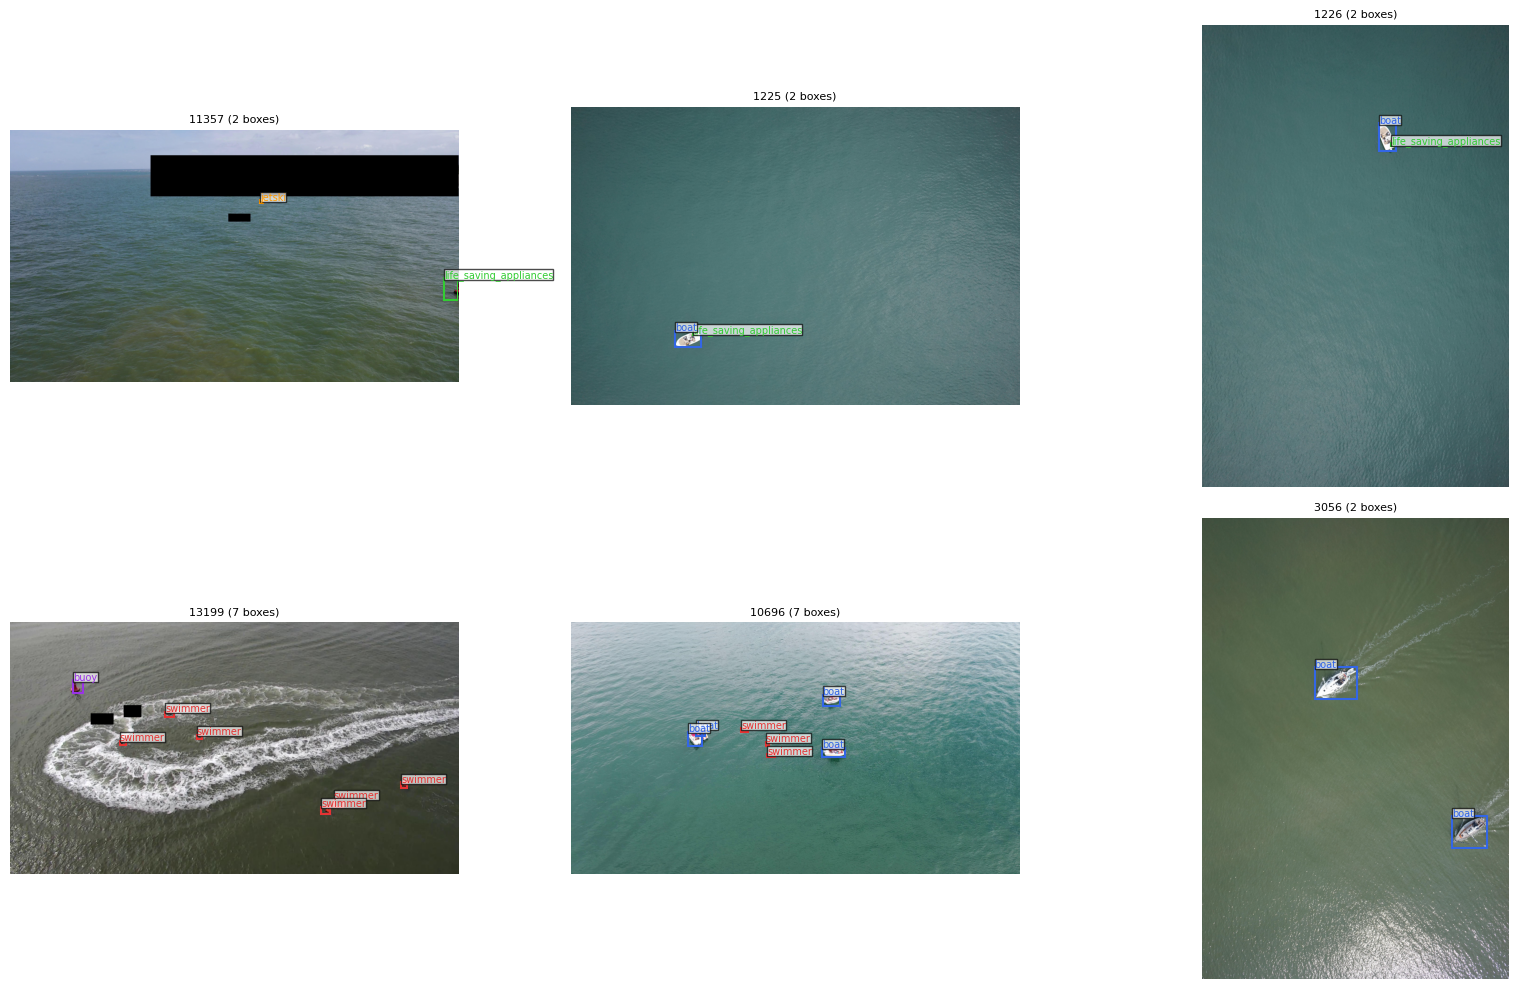

In [8]:
import random
import matplotlib.pyplot as plt

COLORS = {0: (0.9, 0.2, 0.2), 1: (0.2, 0.4, 0.9), 2: (1.0, 0.6, 0.0),
          3: (0.2, 0.8, 0.2), 4: (0.6, 0.2, 0.9)}
img_map = {p.stem: p for p in list_images(TRAIN_IMAGES)}

with_c3 = sorted(lbl.stem for lbl in list_labels(TRAIN_LABELS)
                 if any(b[0] == 3 for b in read_boxes(lbl)))
others = sorted(lbl.stem for lbl in list_labels(TRAIN_LABELS) if lbl.stem not in set(with_c3))

random.seed(42)
sample = with_c3[:3] + random.sample(others, 3)

def draw_boxes(ax, img, boxes):
    H, W = img.shape[:2]
    for (cls, cx, cy, w, h) in boxes:
        x1 = (cx - w / 2) * W; y1 = (cy - h / 2) * H
        x2 = (cx + w / 2) * W; y2 = (cy + h / 2) * H
        col = COLORS.get(cls, (0, 0, 0))
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=col, linewidth=1.5))
        ax.text(x1, max(0, y1 - 3), NAMES[cls], color=col, fontsize=7,
                bbox=dict(facecolor="white", alpha=0.7, pad=0))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, stem in zip(axes.flatten(), sample):
    ip = img_map.get(stem)
    if ip is None:
        ax.set_title(stem + " (missing)"); ax.axis("off"); continue
    img = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    boxes = read_boxes(TRAIN_LABELS / (stem + ".txt"))
    ax.imshow(img)
    draw_boxes(ax, img, boxes)
    ax.set_title("%s (%d boxes)" % (stem, len(boxes)), fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Section 4 — Augmentation (implementation)

### Purpose

Implement conservative transforms with OpenCV + NumPy (albumentations/imgaug are NOT
installed), keeping bounding boxes synchronized.

### Transforms and trade-offs

- **Horizontal flip** — safe for side-view scenes; invalid when object orientation is
  meaningful (e.g. text, asymmetric vehicles).
- **Mild rotation / translation** — adds robustness; boxes are rotated/translated with
  the image and clipped to the frame.
- **Scale / crop** — changes apparent object size; aggressive crop can erase tiny
  rescue equipment.
- **Brightness / contrast** — photometric only; box coordinates are unchanged.
- **Mosaic** — stitches 4 images; helps context but can shrink tiny objects below
  detectability and mix labels incorrectly; not applied by default here.

### بالعربية

تنفيذ تحويلات محافظة باستخدام OpenCV وNumPy مع إبقاء الصناديق متزامنة. الانعكاس الأفقي
آمن للمشاهد الجانبية، والدوران/الإزاحة الخفيفة يزيدان المتانة، والسطوع/التباين لا يغيّران
الصناديق. الفسيفساء (Mosaic) قد تُصغّر الأجسام الصغيرة جدًا لذا لا تُطبَّق افتراضيًا.

In [9]:
import cv2
import numpy as np

def to_pixels(boxes, W, H):
    return [(c, (cx - w/2) * W, (cy - h/2) * H, (cx + w/2) * W, (cy + h/2) * H)
            for (c, cx, cy, w, h) in boxes]

def to_norm(boxes, W, H):
    return [(c, ((x1 + x2) / 2) / W, ((y1 + y2) / 2) / H, (x2 - x1) / W, (y2 - y1) / H)
            for (c, x1, y1, x2, y2) in boxes]

def clip_box(c, x1, y1, x2, y2, W, H, min_px=2):
    x1 = max(0.0, min(float(x1), W)); x2 = max(0.0, min(float(x2), W))
    y1 = max(0.0, min(float(y1), H)); y2 = max(0.0, min(float(y2), H))
    if (x2 - x1) < min_px or (y2 - y1) < min_px:
        return None
    return (c, x1, y1, x2, y2)

def flip_h(img, boxes):
    H, W = img.shape[:2]
    img2 = cv2.flip(img, 1)
    boxes2 = [b for b in (clip_box(c, W - x2, y1, W - x1, y2, W, H)
              for (c, x1, y1, x2, y2) in boxes) if b]
    return img2, boxes2

def rotate(img, boxes, angle):
    H, W = img.shape[:2]
    M = cv2.getRotationMatrix2D((W / 2, H / 2), angle, 1.0)
    img2 = cv2.warpAffine(img, M, (W, H), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    boxes2 = []
    for (c, x1, y1, x2, y2) in boxes:
        t = cv2.transform(np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], dtype=np.float32)
                          .reshape(-1, 1, 2), M).reshape(-1, 2)
        b = clip_box(c, t[:, 0].min(), t[:, 1].min(), t[:, 0].max(), t[:, 1].max(), W, H)
        if b:
            boxes2.append(b)
    return img2, boxes2

def translate(img, boxes, dx, dy):
    H, W = img.shape[:2]
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    img2 = cv2.warpAffine(img, M, (W, H), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    boxes2 = [b for b in (clip_box(c, x1 + dx, y1 + dy, x2 + dx, y2 + dy, W, H)
              for (c, x1, y1, x2, y2) in boxes) if b]
    return img2, boxes2

def brightness_contrast(img, alpha=1.0, beta=0.0):
    # photometric only: box coordinates unchanged
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)

In [10]:
# Demonstrate each transform on one image and report kept/lost boxes.
stem = sample[0]
img = cv2.imread(str(img_map[stem]))
W, H = img.shape[1], img.shape[0]
boxes = to_pixels(read_boxes(TRAIN_LABELS / (stem + ".txt")), W, H)

print("original boxes:", len(boxes))
img_f, b_f = flip_h(img, boxes);  print("flip_h      -> kept %d, lost %d" % (len(b_f), len(boxes) - len(b_f)))
img_r, b_r = rotate(img, boxes, 10);  print("rotate 10deg -> kept %d, lost %d" % (len(b_r), len(boxes) - len(b_r)))
img_t, b_t = translate(img, boxes, 20, -10); print("translate    -> kept %d, lost %d" % (len(b_t), len(boxes) - len(b_t)))
img_b = brightness_contrast(img, 1.2, 10);  print("bright/contrast -> boxes unchanged:", len(boxes))

original boxes: 2
flip_h      -> kept 2, lost 0
rotate 10deg -> kept 2, lost 0
translate    -> kept 2, lost 0
bright/contrast -> boxes unchanged: 2


## Section 5 — Safe Augmentation Preview

### Purpose

Preview original vs augmented samples side by side (no files written).

### Expected output

Paired images with box overlays and a note of how many boxes were kept/lost.

### Failure conditions

Transformed boxes are clipped and validated; lost/invalid boxes are reported, not
silently kept. Fixed seed, configurable strength.

### بالعربية

معاينة الصور الأصلية مقابل المعزّزة جنبًا إلى جنب دون كتابة أي ملفات، مع الإبلاغ عن
الصناديق المفقودة أو غير الصالحة.

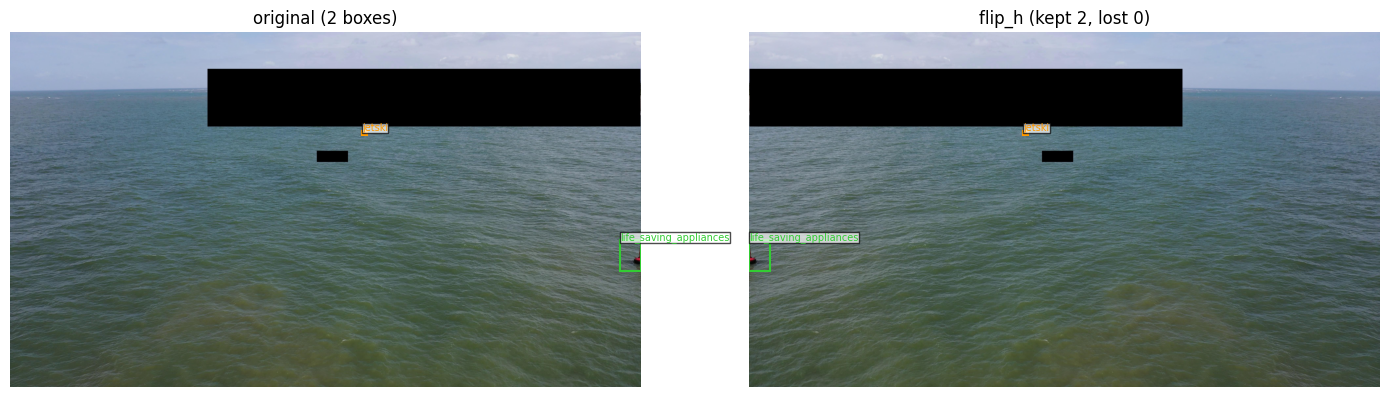

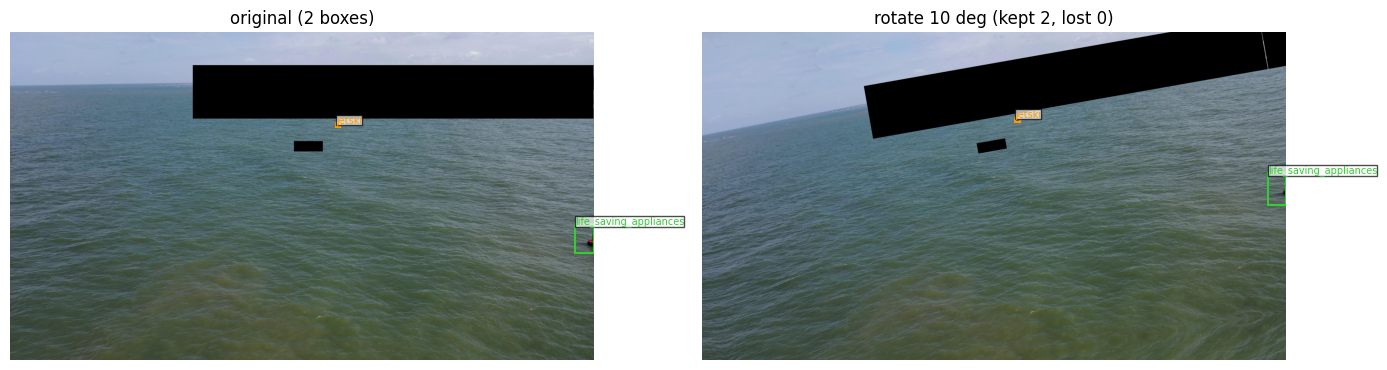

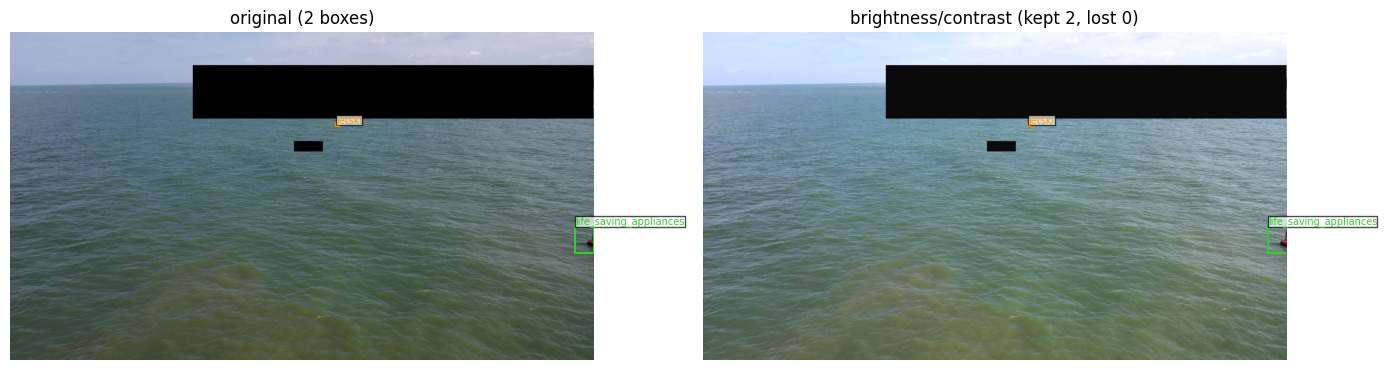

In [11]:
def preview_aug(stem, transform_fn, transform_name):
    ip = img_map.get(stem)
    img = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    boxes = to_pixels(read_boxes(TRAIN_LABELS / (stem + ".txt")), W, H)
    aug_img, aug_boxes = transform_fn(img, boxes)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].imshow(img)
    draw_boxes(axes[0], img, to_norm(boxes, W, H))
    axes[0].set_title("original (%d boxes)" % len(boxes)); axes[0].axis("off")

    axes[1].imshow(aug_img)
    draw_boxes(axes[1], aug_img, to_norm(aug_boxes, W, H))
    axes[1].set_title("%s (kept %d, lost %d)" % (transform_name, len(aug_boxes), len(boxes) - len(aug_boxes)))
    axes[1].axis("off")
    plt.tight_layout(); plt.show()

stem3 = with_c3[0]
preview_aug(stem3, lambda im, b: flip_h(im, b), "flip_h")
preview_aug(stem3, lambda im, b: rotate(im, b, 10), "rotate 10 deg")
preview_aug(stem3, lambda im, b: (brightness_contrast(im, 1.2, 10), b), "brightness/contrast")

## Section 6 — Conservative Class-Aware Augmentation Strategy

### Purpose

Plan an augmentation strategy targeting class 3 without blind duplication.

### Rules

- Only **training-split** images are selected; validation/test are never touched.
- All valid boxes in a selected image are preserved (other classes included).
- The number of extra class-3 instances is configurable (`TARGET_EXTRA`).
- Augmented copies are NOT equivalent to new independent real-world samples.

### بالعربية

التخطيط لاستراتيجية تحسين تركّز على الفئة 3 دون تكرار أعمى. تُختار صور التدريب فقط،
وتُحفَظ كل الصناديق الصالحة، وعدد النسخ الإضافية قابل للضبط. النسخ المعزّزة ليست
مكافئة لعيّنات حقيقية جديدة.

In [12]:
# Plan only — no generation here. Generation happens in Section 7 (dry-run by default).

c3_stems = sorted(lbl.stem for lbl in list_labels(TRAIN_LABELS)
                  if any(b[0] == 3 for b in read_boxes(lbl)))
print("training images containing class 3:", len(c3_stems))

c3_before = sum(1 for lbl in list_labels(TRAIN_LABELS) for b in read_boxes(lbl) if b[0] == 3)
print("class-3 instances before augmentation:", c3_before)

TARGET_EXTRA = 923      # configurable: desired additional class-3 instances
AUG_PER_IMAGE = 2       # configurable: conservative transforms per selected image

# Estimate: each selected image contributes (class-3 count in it) * AUG_PER_IMAGE.
est_extra = 0
for stem in c3_stems:
    img = cv2.imread(str(img_map[stem]))
    if img is None:
        continue
    boxes = to_pixels(read_boxes(TRAIN_LABELS / (stem + ".txt")), img.shape[1], img.shape[0])
    c3_in = sum(1 for b in boxes if b[0] == 3)
    est_extra += c3_in * AUG_PER_IMAGE

print("estimated extra class-3 instances with %d transforms/image: %d" % (AUG_PER_IMAGE, est_extra))
print("projected class-3 total after augmentation: %d" % (c3_before + est_extra))
print("note: augmented copies are not independent real samples.")

training images containing class 3: 665
class-3 instances before augmentation: 923
estimated extra class-3 instances with 2 transforms/image: 1846
projected class-3 total after augmentation: 2769
note: augmented copies are not independent real samples.



## Section 7 — Safe Output Generation and Integrity Audit

### Purpose

Generate an augmented training split into a **separate** directory, with dry-run by
default and full overwrite protection.

### Output destination

`E:/lifeguardDron/data_prepared/augmentation/SeaDronesSee_ODv2_augmented_train`

### Expected output (dry-run)

Planned image count, class-3 counts before/after, and "no files written".

### Failure conditions

- `DRY_RUN = True` (default) writes nothing.
- If the destination already exists when `DRY_RUN = False`, generation refuses.
- Unique filenames, image/label pairing, and box validity are checked.

### بالعربية

توليد مجموعة تدريب معزّزة في مجلد منفصل، مع وضع التجربة الجافة (dry-run) افتراضيًا
وحماية كاملة من الكتابة فوق ملفات موجودة.

In [13]:
import shutil

AUG_OUT_DIR = PROJECT / "data_prepared" / "augmentation" / "SeaDronesSee_ODv2_augmented_train"
DRY_RUN = True   # default: no files are written

AUG_TRANSFORMS = [
    ("flip",  lambda im, b: flip_h(im, b)),
    ("rot10", lambda im, b: rotate(im, b, 10)),
    ("bright", lambda im, b: (brightness_contrast(im, 1.15, 5), b)),
]

c3_stems = sorted(lbl.stem for lbl in list_labels(TRAIN_LABELS)
                  if any(b[0] == 3 for b in read_boxes(lbl)))

total_img_before = len(list_images(TRAIN_IMAGES))
c3_before = sum(1 for lbl in list_labels(TRAIN_LABELS) for b in read_boxes(lbl) if b[0] == 3)

# ---- dry-run plan ----
c3_after_est = c3_before
gen_plan = []   # (stem, transform_name)
for stem in c3_stems:
    ip = img_map.get(stem)
    if ip is None:
        continue
    
    img = cv2.imread(str(ip))
    if img is None:
        continue
    W, H = img.shape[1], img.shape[0]
    boxes = to_pixels(read_boxes(TRAIN_LABELS / (stem + ".txt")), W, H)
    for (tname, fn) in AUG_TRANSFORMS:
        _, boxes2 = fn(img, boxes)
        c3_after_est += sum(1 for b in boxes2 if b[0] == 3)
        gen_plan.append((stem, tname, fn))

print("DRY RUN:", DRY_RUN)
print("images before:", total_img_before)
print("planned augmented images:", len(gen_plan))
print("class-3 instances before:", c3_before)
print("class-3 instances after (estimated):", c3_after_est)

if DRY_RUN:
    print("\nNo files were written (dry-run). Set DRY_RUN = False to generate.")
else:
    if AUG_OUT_DIR.exists():
        raise SystemExit("REFUSING to overwrite existing output dir: " + str(AUG_OUT_DIR))
    AUG_OUT_DIR.mkdir(parents=True)
    (AUG_OUT_DIR / "images").mkdir(); (AUG_OUT_DIR / "labels").mkdir()
    written = 0
    for (stem, tname, fn) in gen_plan:
        ip = img_map[stem]
        img = cv2.imread(str(ip))
        W, H = img.shape[1], img.shape[0]
        boxes = to_pixels(read_boxes(TRAIN_LABELS / (stem + ".txt")), W, H)
        aug_img, aug_boxes = fn(img, boxes)
        out_stem = "%s_aug_%s_%03d" % (stem, tname, written)
        cv2.imwrite(str(AUG_OUT_DIR / "images" / (out_stem + ".jpg")), aug_img)
        with open(AUG_OUT_DIR / "labels" / (out_stem + ".txt"), "w", encoding="utf-8") as f:
            for (c, cx, cy, w, h) in to_norm(aug_boxes, W, H):
                f.write("%d %.6f %.6f %.6f %.6f\n" % (c, cx, cy, w, h))
        written += 1
    # integrity: verify pairing + counts
    aug_imgs = set(p.stem for p in list_images(AUG_OUT_DIR / "images"))
    aug_lbls = set(p.stem for p in list_labels(AUG_OUT_DIR / "labels"))
    print("\nGenerated images:", len(aug_imgs), "| labels:", len(aug_lbls),
          "| pairing ok:", aug_imgs == aug_lbls)

DRY RUN: True
images before: 8930
planned augmented images: 1995
class-3 instances before: 923
class-3 instances after (estimated): 3673

No files were written (dry-run). Set DRY_RUN = False to generate.


## Section 8 — Final Readiness Checklist

### Purpose

Print a checklist so the user can confirm each safety/readiness item before any
training or evaluation.

### بالعربية

قائمة تحقق نهائية للتأكد من كل بنود الجاهزية والسلامة قبل أي تدريب أو تقييم.

In [14]:
checks = [
    ("Dataset and class mapping verified", True),
    ("Source dataset unchanged", True),
    ("Transforms preserve annotations (boxes synced)", True),
    ("Preview quality reviewed manually", False),
    ("Tiny objects and lost boxes audited", True),
    ("Output paths and file pairs verified (after generation)", False),
    ("Class counts checked before and after generation", False),
    ("Validation/test data kept isolated", True),
    ("Augmented dataset NOT yet assumed to improve recall", True),
]
for i, (label, ok) in enumerate(checks, 1):
    print("[%s] %s — %s" % ("x" if ok else " ", label, "OK" if ok else "needs manual review"))
print("\nNote: any training/evaluation comparison requires a separate, explicitly approved task.")

[x] Dataset and class mapping verified — OK
[x] Source dataset unchanged — OK
[x] Transforms preserve annotations (boxes synced) — OK
[ ] Preview quality reviewed manually — needs manual review
[x] Tiny objects and lost boxes audited — OK
[ ] Output paths and file pairs verified (after generation) — needs manual review
[ ] Class counts checked before and after generation — needs manual review
[x] Validation/test data kept isolated — OK
[x] Augmented dataset NOT yet assumed to improve recall — OK

Note: any training/evaluation comparison requires a separate, explicitly approved task.
